WORKFLOW
1. Load clean speech
    - Inspect their sampling rates, lengths, and amplitudes. Convert recordings to a common sampling rate if needed.
    - Plot the clean speech waveform and spectrogram.
2. Generate noisy speech
    - Add synthetic noise to the original clean recordings (eg. white gaussian noise, babble noise?)
3. Divide signal into frames
    - Speech is non-stationary --> its statistical characteristics change over time
    - But speech can be treated as roughly stationary within short frames
    - Can use short-time Fourier transform (STFT) with initial configurations:
        - Sampling frequency
        - Frame duration
        - Frame length
        - Overlap
        - Window
        - FFT length
4. Estimate noise and speech PSD
    - Estimate the noise power spectrum by averaging the squared STFT magnitues across noise-only frames
5. Apply enhancement algorithms
6. Evaluate performance
7. Compare the algorithms

In [1]:
# Import libraries
import numpy as np
import scipy
import matplotlib.pyplot as plt
import soundfile as sf
import librosa

In [2]:
# Load clean speech
clean_speech, fs = sf.read("clean speech.wav")

# Load noise signals
babble_noise, fs_babble = sf.read("babble noise.wav")
stationary_noise, fs_stationary = sf.read(
    "stationary speech-shaped noise.wav"
)

# Display information
print("Clean speech:")
print("Sampling rate:", fs)
print("Duration:", len(clean_speech) / fs, "seconds")
print("Shape:", clean_speech.shape)

print("\nBabble noise:")
print("Sampling rate:", fs_babble)
print("Duration:", len(babble_noise) / fs_babble, "seconds")

print("\nStationary noise:")
print("Sampling rate:", fs_stationary)
print("Duration:", len(stationary_noise) / fs_stationary, "seconds")

Clean speech:
Sampling rate: 16000
Duration: 36.1034375 seconds
Shape: (577655,)

Babble noise:
Sampling rate: 16000
Duration: 37.5000625 seconds

Stationary noise:
Sampling rate: 16000
Duration: 90.0 seconds


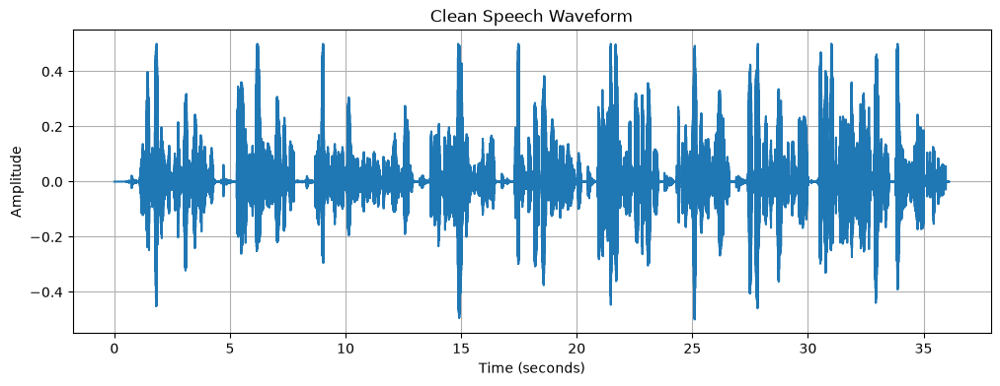

In [3]:
# Time axis
time = np.arange(len(clean_speech)) / fs

plt.figure(figsize=(12, 4))

plt.plot(time, clean_speech)
# plt.plot(time, babble_noise)
# plt.plot(time, stationary_noise)

plt.title("Clean Speech Waveform")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid(True)

plt.show()

c:\Users\laura\Github\Speech_Enhancement\.venv\Lib\site-packages\matplotlib\axes\_axes.py:8647: RuntimeWarning: divide by zero encountered in log10
  Z = 10. * np.log10(spec)


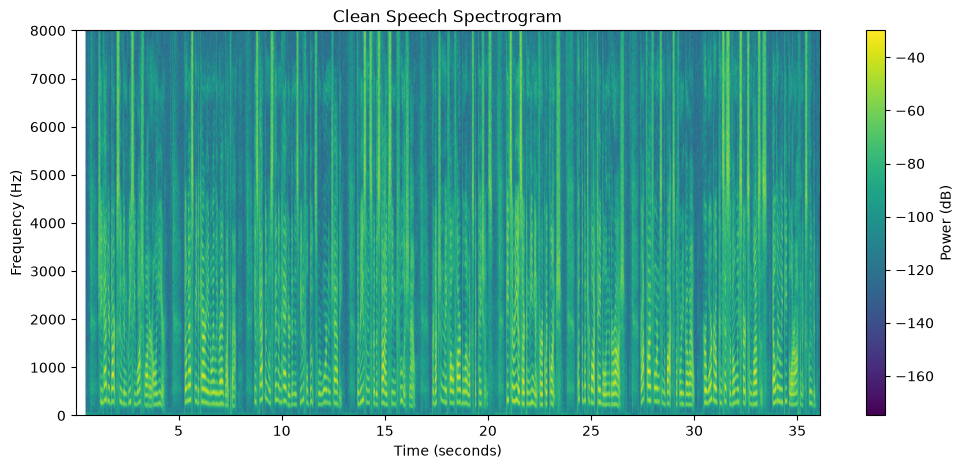

In [4]:
plt.figure(figsize=(12, 5))

plt.specgram(
    clean_speech,
    Fs=fs,
    NFFT=512,
    noverlap=256,
    cmap="viridis"
)

plt.title("Clean Speech Spectrogram")
plt.xlabel("Time (seconds)")
plt.ylabel("Frequency (Hz)")
plt.colorbar(label="Power (dB)")

plt.show()

- All three audio recordings have the same sampling frequency = 16000Hz (no need to resample)
- Clean speech waveform : Can identify periods of speech activity and short pauses between utterances.
- Spectrogram : 
    - Horizontal bands: Harmonics associated with voiced speech.
    - Vertical patterns: Rapid changes in speech, such as consonants and transitions.
    - Concentrated energy below approximately 4,000 Hz: Much of the visible speech energy lies in the lower-frequency range.

In [5]:
# Add noise to clean speech at a specified SNR
# Function to generate noisy speech
def add_noise(clean, noise, target_snr_db):

    # Make sure noise is long enough
    if len(noise) < len(clean):
        repeats = int(np.ceil(len(clean) / len(noise)))
        noise = np.tile(noise, repeats)

    # Match noise length to speech
    noise = noise[:len(clean)]

    # Calculate average signal power
    speech_power = np.mean(clean**2)
    noise_power = np.mean(noise**2)

    # Calculate desired noise power
    target_noise_power = speech_power / (10**(target_snr_db / 10))

    # Scale noise
    scaling_factor = np.sqrt(target_noise_power / noise_power)

    scaled_noise = noise * scaling_factor

    # Add noise to clean speech
    noisy = clean + scaled_noise

    return noisy, scaled_noise

In [6]:
# Generate noisy speech
# Desired SNR
target_snr = 0

# Generate noisy speech
noisy_babble, scaled_babble = add_noise(
    clean_speech,
    babble_noise,
    target_snr
)

noisy_stationary, scaled_stationary = add_noise(
    clean_speech,
    stationary_noise,
    target_snr
)

print("Babble noise shape:", noisy_babble.shape)
print("Stationary noise shape:", noisy_stationary.shape)

Babble noise shape: (577655,)
Stationary noise shape: (577655,)


In [7]:
def calculate_snr(clean, noise):
    speech_power = np.mean(clean**2)
    noise_power = np.mean(noise**2)

    return 10 * np.log10(speech_power / noise_power)


print(
    "Babble SNR:",
    calculate_snr(clean_speech, scaled_babble),
    "dB"
)

print(
    "Stationary SNR:",
    calculate_snr(clean_speech, scaled_stationary),
    "dB"
)

Babble SNR: 0.0 dB
Stationary SNR: -4.821637332766436e-16 dB


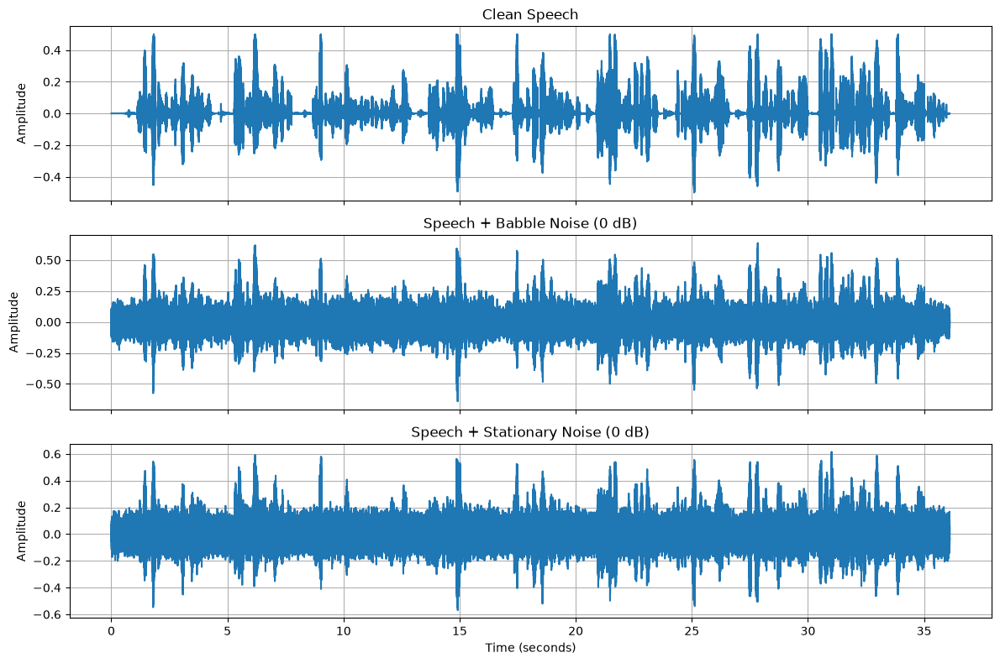

In [8]:
# Plot waveforms of clean and noisy speech
time = np.arange(len(clean_speech)) / fs

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)

axes[0].plot(time, clean_speech)
axes[0].set_title("Clean Speech")

axes[1].plot(time, noisy_babble)
axes[1].set_title("Speech + Babble Noise (0 dB)")

axes[2].plot(time, noisy_stationary)
axes[2].set_title("Speech + Stationary Noise (0 dB)")

for ax in axes:
    ax.set_ylabel("Amplitude")
    ax.grid(True)

axes[-1].set_xlabel("Time (seconds)")

plt.tight_layout()
plt.show()

In [ ]:
from IPython.display import Audio, display

print("Original clean speech:")
display(Audio(clean_speech, rate=fs))
# display(Audio(clean_speech[int(0*fs):int(0.4*fs)], rate=fs))

print("Speech with babble noise:")
display(Audio(noisy_babble, rate=fs))

print("Speech with stationary noise:")
display(Audio(noisy_stationary, rate=fs))

Original clean speech:


Speech with babble noise:


Speech with stationary noise:


Short-Time Fourier Transform (STFT)

In [10]:
# Define STFT parameters
from scipy.signal import stft, istft
import numpy as np
import matplotlib.pyplot as plt

# STFT parameters
nperseg = 512       # Frame length = 32 ms at 16 kHz
noverlap = 256      # 50% overlap
nfft = 512          # FFT length
window = "hann"

print("Frame duration:", nperseg / fs * 1000, "ms")
print("Overlap:", noverlap / nperseg * 100, "%")
print("Frequency resolution:", fs / nfft, "Hz")

Frame duration: 32.0 ms
Overlap: 50.0 %
Frequency resolution: 31.25 Hz


Output:
Frame duration: 32.0 ms
Overlap: 50.0 %
Frequency resolution: 31.25 Hz (FFT-bin spacing)

In [11]:
# Calculate the STFT
# Clean speech
f, t, S = stft(
    clean_speech,
    fs=fs,
    window=window,
    nperseg=nperseg,
    noverlap=noverlap,
    nfft=nfft
)

# Speech with babble noise
_, _, Y_babble = stft(
    noisy_babble,
    fs=fs,
    window=window,
    nperseg=nperseg,
    noverlap=noverlap,
    nfft=nfft
)

# Speech with stationary noise
_, _, Y_stationary = stft(
    noisy_stationary,
    fs=fs,
    window=window,
    nperseg=nperseg,
    noverlap=noverlap,
    nfft=nfft
)

print("Clean STFT shape:", S.shape)
print("Babble STFT shape:", Y_babble.shape)
print("Stationary STFT shape:", Y_stationary.shape)

Clean STFT shape: (257, 2258)
Babble STFT shape: (257, 2258)
Stationary STFT shape: (257, 2258)


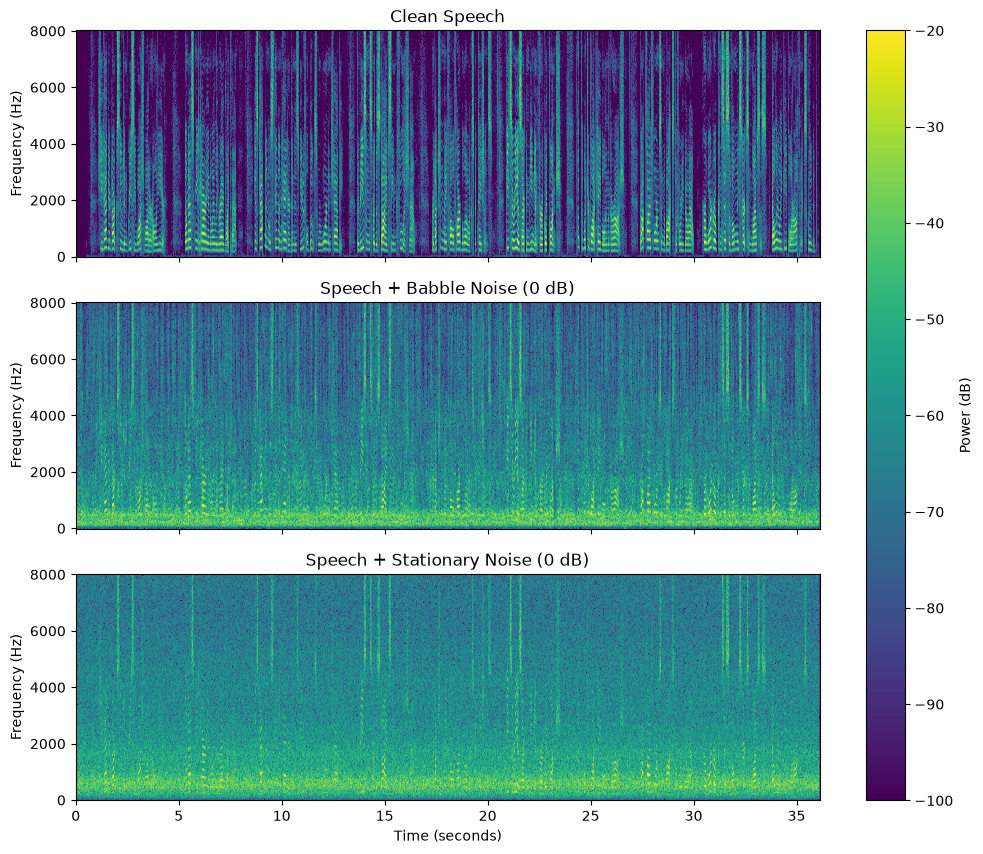

In [12]:
# Plot the spectrograms
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

signals = [
    (S, "Clean Speech"),
    (Y_babble, "Speech + Babble Noise (0 dB)"),
    (Y_stationary, "Speech + Stationary Noise (0 dB)")
]

for ax, (Z, title) in zip(axes, signals):

    power_db = 10 * np.log10(np.abs(Z)**2 + 1e-12)

    im = ax.pcolormesh(
        t,
        f,
        power_db,
        shading="auto",
        cmap="viridis",
        vmin=-100,
        vmax=-20
    )

    ax.set_title(title)
    ax.set_ylabel("Frequency (Hz)")

axes[-1].set_xlabel("Time (seconds)")

fig.colorbar(
    im,
    ax=axes,
    label="Power (dB)"
)

plt.show()

In [13]:
# Reconstruct clean speech using inverse STFT
_, reconstructed = istft(
    S,
    fs=fs,
    window=window,
    nperseg=nperseg,
    noverlap=noverlap,
    nfft=nfft
)

# Match original length
reconstructed = reconstructed[:len(clean_speech)]

# Reconstruction error
mse = np.mean((clean_speech - reconstructed)**2)

print("STFT reconstruction MSE:", mse)

STFT reconstruction MSE: 1.802178668666816e-34



STEP 4 : ESTIMATING SPEECH & NOISE PSDs
-----------------------------------------

In [14]:
# STFT of scaled babble noise
_, _, N_babble = stft(
    scaled_babble,
    fs=fs,
    window=window,
    nperseg=nperseg,
    noverlap=noverlap,
    nfft=nfft
)

# STFT of scaled stationary noise
_, _, N_stationary = stft(
    scaled_stationary,
    fs=fs,
    window=window,
    nperseg=nperseg,
    noverlap=noverlap,
    nfft=nfft
)

print("Babble noise STFT:", N_babble.shape)
print("Stationary noise STFT:", N_stationary.shape)

Babble noise STFT: (257, 2258)
Stationary noise STFT: (257, 2258)


In [15]:
# Estimate noise power spectra by averaging across time frames
psd_babble = np.mean(np.abs(N_babble)**2, axis=1)

psd_stationary = np.mean(np.abs(N_stationary)**2, axis=1)

print("Babble PSD shape:", psd_babble.shape)
print("Stationary PSD shape:", psd_stationary.shape)

Babble PSD shape: (257,)
Stationary PSD shape: (257,)


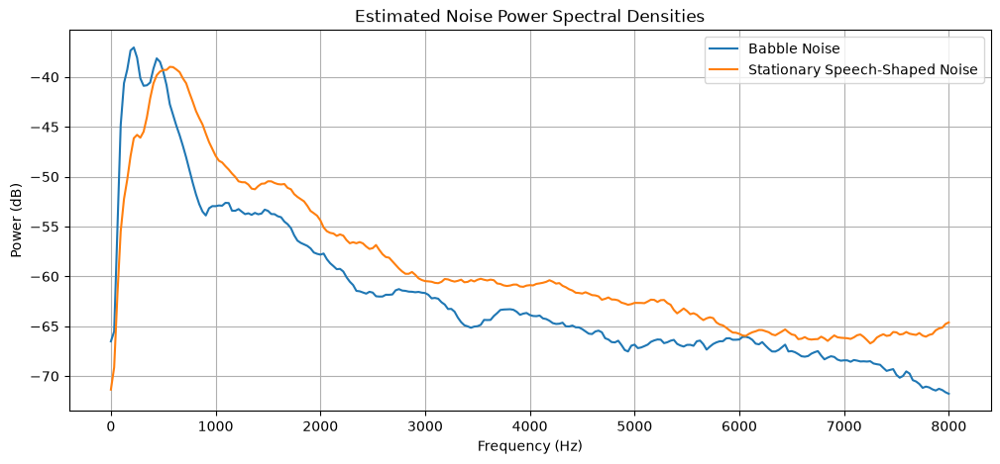

In [16]:
plt.figure(figsize=(12, 5))

plt.plot(
    f,
    10 * np.log10(psd_babble + 1e-12),
    label="Babble Noise"
)

plt.plot(
    f,
    10 * np.log10(psd_stationary + 1e-12),
    label="Stationary Speech-Shaped Noise"
)

plt.title("Estimated Noise Power Spectral Densities")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (dB)")
plt.legend()
plt.grid(True)

plt.show()

In [17]:
# Estimate speech PSD from noisy speech

eps = 1e-12 # very small value to avoid log(0)

speech_psd_babble = np.maximum(
    np.abs(Y_babble)**2 - psd_babble[:, None],
    0
)

speech_psd_stationary = np.maximum(
    np.abs(Y_stationary)**2 - psd_stationary[:, None],
    0
)

print("Speech PSD (babble):", speech_psd_babble.shape)
print("Speech PSD (stationary):", speech_psd_stationary.shape)

Speech PSD (babble): (257, 2258)
Speech PSD (stationary): (257, 2258)


STEP 5 : IMPLEMENT SPEECH ENHANCEMENT ALGORITHMS
------------------------------------------------

In [18]:
def wiener_filter(Y, speech_psd, noise_psd, eps=1e-12):

    # Wiener filter frequency response
    H = speech_psd / (
        speech_psd + noise_psd[:, None] + eps
    )

    # Apply filter
    S_hat = H * Y

    return S_hat, H

In [19]:
# Apply Wiener filtering
# Wiener filtering: babble noise
S_hat_babble, H_babble = wiener_filter(
    Y_babble,
    speech_psd_babble,
    psd_babble
)

# Wiener filtering: stationary noise
S_hat_stationary, H_stationary = wiener_filter(
    Y_stationary,
    speech_psd_stationary,
    psd_stationary
)

print("Babble enhanced STFT:", S_hat_babble.shape)
print("Stationary enhanced STFT:", S_hat_stationary.shape)

Babble enhanced STFT: (257, 2258)
Stationary enhanced STFT: (257, 2258)


In [20]:
# Reconstruct enhanced babble speech
_, enhanced_babble = istft(
    S_hat_babble,
    fs=fs,
    window=window,
    nperseg=nperseg,
    noverlap=noverlap,
    nfft=nfft
)

# Reconstruct enhanced stationary speech
_, enhanced_stationary = istft(
    S_hat_stationary,
    fs=fs,
    window=window,
    nperseg=nperseg,
    noverlap=noverlap,
    nfft=nfft
)

# Match original signal length
enhanced_babble = enhanced_babble[:len(clean_speech)]
enhanced_stationary = enhanced_stationary[:len(clean_speech)]

print("Enhanced babble shape:", enhanced_babble.shape)
print("Enhanced stationary shape:", enhanced_stationary.shape)

Enhanced babble shape: (577655,)
Enhanced stationary shape: (577655,)


In [21]:
print("Original clean speech:")
display(Audio(clean_speech, rate=fs, normalize=False))

print("Babble noise — Before enhancement:")
display(Audio(noisy_babble, rate=fs, normalize=False))

print("Babble noise — After Wiener filtering:")
display(Audio(enhanced_babble, rate=fs, normalize=False))

print("Stationary noise — Before enhancement:")
display(Audio(noisy_stationary, rate=fs, normalize=False))

print("Stationary noise — After Wiener filtering:")
display(Audio(enhanced_stationary, rate=fs, normalize=False))

Original clean speech:


Babble noise — Before enhancement:


Babble noise — After Wiener filtering:


Stationary noise — Before enhancement:


Stationary noise — After Wiener filtering:


COMMENTS ON THE AUDIO RESULTS:
- Babble noise
    - bcackground noise more quieter
    - speech somewhat easier to understand, some words/parts clearer than others
    - some distortion and unnatural sounds
- Stationary noise
    - background noise is quieter
    - lots of unnatural noise, weird static
    - a bit noiser still than the results of babble noise

In [22]:
def spectral_subtraction(Y, noise_psd, eps=1e-12):
    # Noisy speech power spectrum
    noisy_power = np.abs(Y)**2

    # Subtract estimated noise power
    clean_power = np.maximum(
        noisy_power - noise_psd[:, None],
        0
    )

    # Convert power to magnitude
    clean_magnitude = np.sqrt(clean_power)

    # Preserve noisy phase
    noisy_phase = np.exp(1j * np.angle(Y))

    # Reconstruct enhanced STFT
    S_hat = clean_magnitude * noisy_phase

    return S_hat

In [23]:
# Apply spectral subtraction
S_sub_babble = spectral_subtraction(
    Y_babble,
    psd_babble
)

S_sub_stationary = spectral_subtraction(
    Y_stationary,
    psd_stationary
)

# Reconstruct audio
_, sub_babble = istft(
    S_sub_babble,
    fs=fs,
    window=window,
    nperseg=nperseg,
    noverlap=noverlap,
    nfft=nfft
)

_, sub_stationary = istft(
    S_sub_stationary,
    fs=fs,
    window=window,
    nperseg=nperseg,
    noverlap=noverlap,
    nfft=nfft
)

# Match original length
sub_babble = sub_babble[:len(clean_speech)]
sub_stationary = sub_stationary[:len(clean_speech)]

In [24]:
print("BABBLE NOISE")

print("Noisy speech:")
display(Audio(noisy_babble, rate=fs, normalize=False))

print("Wiener filtering:")
display(Audio(enhanced_babble, rate=fs, normalize=False))

print("Spectral subtraction:")
display(Audio(sub_babble, rate=fs, normalize=False))

BABBLE NOISE
Noisy speech:


Wiener filtering:


Spectral subtraction:


STEP 6 : EVALUATE ENHANCEMENT PERFORMANCE
------------------------------------------

In [25]:
def calculate_mse(clean, enhanced):
    return np.mean((clean - enhanced)**2)

In [26]:
def calculate_rmse(clean, enhanced):
    return np.sqrt(calculate_mse(clean, enhanced))

In [27]:
def calculate_output_snr(clean, enhanced):
    signal_power = np.mean(clean**2)
    error_power = np.mean((clean - enhanced)**2)

    return 10 * np.log10(
        signal_power / (error_power + 1e-20)
    )

In [28]:
import pandas as pd

results = []

signals = {
    "Babble": {
        "Noisy": noisy_babble,
        "Wiener": enhanced_babble,
        "Spectral Subtraction": sub_babble
    },
    "Stationary": {
        "Noisy": noisy_stationary,
        "Wiener": enhanced_stationary,
        "Spectral Subtraction": sub_stationary
    }
}

for noise_type, methods in signals.items():

    input_snr = calculate_output_snr(
        clean_speech,
        methods["Noisy"]
    )

    for method, signal in methods.items():

        output_snr = calculate_output_snr(
            clean_speech,
            signal
        )

        results.append({
            "Noise Type": noise_type,
            "Method": method,
            "MSE": calculate_mse(clean_speech, signal),
            "RMSE": calculate_rmse(clean_speech, signal),
            "Output SNR (dB)": output_snr,
            "SNR Improvement (dB)": output_snr - input_snr
        })

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Noise Type,Method,MSE,RMSE,Output SNR (dB),SNR Improvement (dB)
0,Babble,Noisy,0.0029,0.0538,0.0000,0.0000
1,Babble,Wiener,0.0010,0.0311,4.7709,4.7709
2,Babble,Spectral Subtraction,0.0013,0.0363,3.4238,3.4238
3,Stationary,Noisy,0.0029,0.0538,-0.0000,0.0000
4,Stationary,Wiener,0.0008,0.0284,5.5528,5.5528
5,Stationary,Spectral Subtraction,0.0012,0.0342,3.9538,3.9538


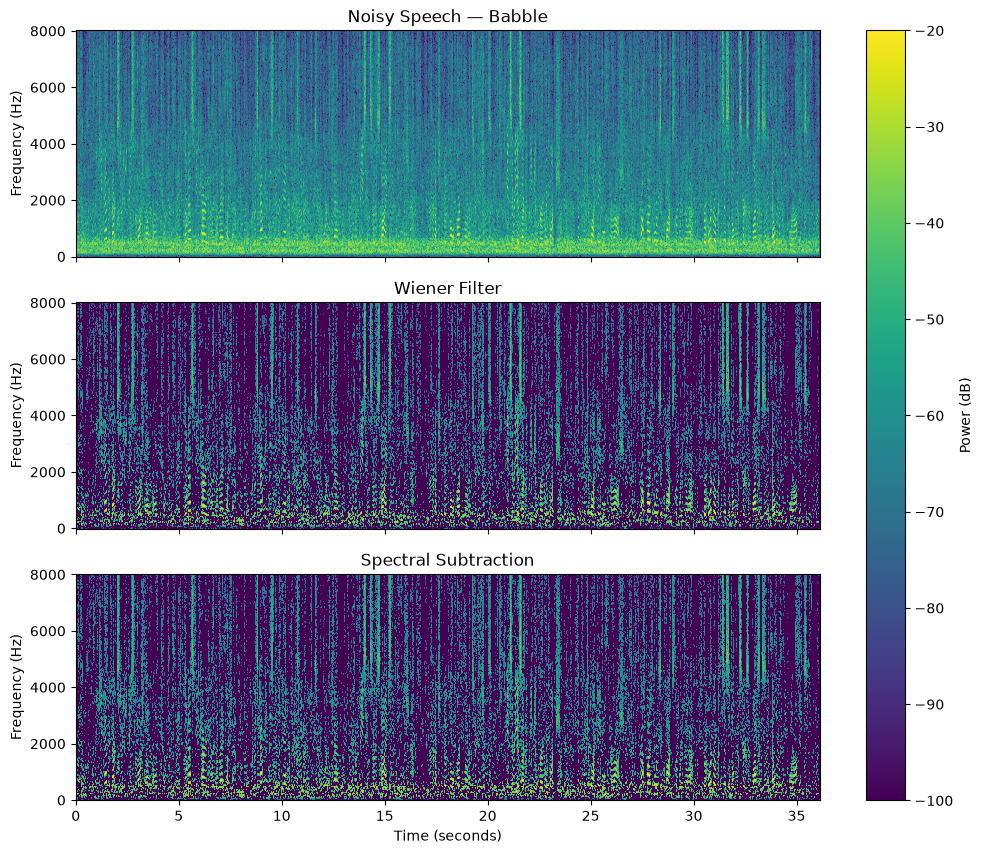

In [ ]:
# Visualize the comparison
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

spectrograms = [
    (Y_babble, "Noisy Speech — Babble"),
    (S_hat_babble, "Wiener Filter"),
    (S_sub_babble, "Spectral Subtraction")
]

for ax, (Z, title) in zip(axes, spectrograms):

    power_db = 10 * np.log10(
        np.abs(Z)**2 + 1e-12
    )

    im = ax.pcolormesh(
        t,
        f,
        power_db,
        shading="auto",
        cmap="viridis",
        vmin=-100,
        vmax=-20
    )

    ax.set_title(title)
    ax.set_ylabel("Frequency (Hz)")

axes[-1].set_xlabel("Time (seconds)")

fig.colorbar(
    im,
    ax=axes,
    label="Power (dB)"
)

plt.show()

Wiener gain range: 0.0 0.9997261889137005
Spectral subtraction gain range: 0.0 0.9998630858347038
Mean difference: 5.61165676156322e-07


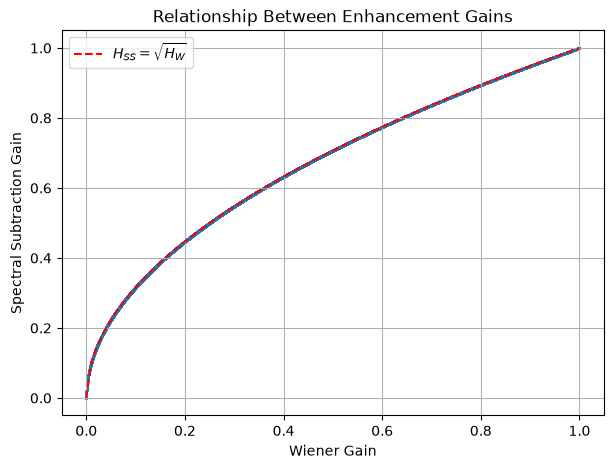

In [ ]:
# VERIFYING THE RELATIONSHIP BETWEEN WIENER AND SPECTRAL SUBTRACTION GAINS
# Equivalent spectral subtraction gain
H_sub_babble = np.sqrt(
    np.maximum(
        1 - psd_babble[:, None] /
        (np.abs(Y_babble)**2 + 1e-12),
        0
    )
)

# Compare Wiener and spectral subtraction gains
print("Wiener gain range:",
      H_babble.min(), H_babble.max())

print("Spectral subtraction gain range:",
      H_sub_babble.min(), H_sub_babble.max())

# Compare the relationship between gains
difference = np.mean(
    np.abs(H_sub_babble - np.sqrt(H_babble))
)

print("Mean difference:", difference)

# Visualizing the relationship between Wiener and spectral subtraction gains
plt.figure(figsize=(7, 5))

plt.scatter(
    H_babble.flatten(),
    H_sub_babble.flatten(),
    s=1,
    alpha=0.1
)

x = np.linspace(0, 1, 100)

plt.plot(x, np.sqrt(x), "r--",
         label=r"$H_{SS}=\sqrt{H_W}$")

plt.xlabel("Wiener Gain")
plt.ylabel("Spectral Subtraction Gain")
plt.title("Relationship Between Enhancement Gains")
plt.legend()
plt.grid(True)

plt.show()

STEP 7 : IMPLEMENT REALISTIC WIENER FILTER
------------------------------------------
What's been done so far:
- Wiener filtering using known noise recordings
- Spectral subtraction using known noise recordings
- Evaluation using MSE, RMSE and SNR improvement

BUT NOW: Estimate the noise PSD directly from the noisy speech recording

Use the pauses in the speech recording to take a segment of the noisy recording without speech. Then, estimate the noise PSD using that segment.

In [33]:
# Noise estimation parameters
noise_duration = 0.3  # First 0.3 seconds assumed noise-only

def estimate_noise_psd(Y, t, noise_duration=0.3):
    """
    Estimate noise PSD using an initial noise-only segment.

    Parameters
    ----------
    Y : ndarray
        STFT of noisy speech (frequency x time).
    t : ndarray
        STFT time frame positions.
    noise_duration : float
        Duration of initial noise-only segment (seconds).

    Returns
    -------
    noise_psd : ndarray
        Estimated noise PSD (frequency,).
    """

    # Select frames within initial noise-only interval
    # Exclude frames extending beyond that interval
    mask = (t >= nperseg / (2 * fs)) & (
        t + nperseg / (2 * fs) <= noise_duration
    )

    noise_frames = Y[:, mask]

    if noise_frames.shape[1] == 0:
        raise ValueError("No noise-only frames selected.")

    # Average periodograms
    noise_psd = np.mean(
        np.abs(noise_frames)**2,
        axis=1
    )

    return noise_psd


# Estimate noise PSD using noisy speech only
psd_babble_est = estimate_noise_psd(
    Y_babble, t, noise_duration
)

psd_stationary_est = estimate_noise_psd(
    Y_stationary, t, noise_duration
)

print("Estimated babble PSD:", psd_babble_est.shape)
print("Estimated stationary PSD:", psd_stationary_est.shape)

Estimated babble PSD: (257,)
Estimated stationary PSD: (257,)
